# Import required libraries

In [583]:
import os
import math
import numpy as np
from collections import Counter
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns
import random

# Load & Split dataset

In [584]:
def Load_split(data_dir):
    sentences_path = os.path.join(data_dir, 'datasetSentences.txt')
    splits_path = os.path.join(data_dir, 'datasetSplit.txt')
    dictionary_path = os.path.join(data_dir, 'dictionary.txt')
    labels_path = os.path.join(data_dir, 'sentiment_labels.txt')
    
    with open(sentences_path, 'r', encoding='utf-8') as f:
        sentences = [line.strip().split('\t')[1] for line in f.readlines()[1:]]
    with open(splits_path, 'r', encoding='utf-8') as f:
        splits = [int(line.strip().split(',')[1]) for line in f.readlines()[1:]]
    phrase_to_id = {}
    with open(dictionary_path, 'r', encoding='utf-8') as f:
        for line in f:
            phrase, phrase_id = line.strip().split('|')
            phrase_to_id[phrase] = int(phrase_id)
    id_to_label = {}
    with open(labels_path, 'r', encoding='utf-8') as f:
        for line in f.readlines()[1:]:
            phrase_id, label = line.strip().split('|')
            id_to_label[int(phrase_id)] = float(label)
    
    train_data, test_data = [], []
    for i, sentence in enumerate(sentences):
        phrase_id = phrase_to_id.get(sentence)
        if phrase_id and phrase_id in id_to_label:
            label = id_to_label[phrase_id]
            if splits[i] == 1:  # Train
                train_data.append({'sentence': sentence, 'label': label})
            elif splits[i] == 2:  # Test
                test_data.append({'sentence': sentence, 'label': label})
    return train_data, test_data

# Converting to classes

In [585]:
def Classes_convertion(label):
    if label <= 0.2:
        return 0
    elif label <= 0.4:
        return 1
    elif label <= 0.6:
        return 2
    elif label <= 0.8:
        return 3
    else:
        return 4

# Balance Classes

In [586]:
def balance_classes(train_data):
    # Convert labels to classes and count distribution
    class_counts = Counter([Classes_convertion(item['label']) for item in train_data])
    print("Original class distribution:", dict(class_counts))
    
    min_class_size = min(class_counts.values())
    
    # downsampling
    balanced_data = []
    for class_label in range(5):  # 5 classes (0-4)
        class_samples = [item for item in train_data 
                        if Classes_convertion(item['label']) == class_label]
        balanced_class_samples = random.sample(class_samples, min_class_size)
        balanced_data.extend(balanced_class_samples)
    
        new_distribution = Counter([Classes_convertion(item['label']) 
                              for item in balanced_data])
    print("Balanced class distribution:", dict(new_distribution))

    random.shuffle(balanced_data)
    
    return balanced_data

# Naive Bayes

## Naive Bayes (From Scratch)

#### NB_Training

In [587]:
def train_NB(train_data):
    
    D = [(ex['sentence'], Classes_convertion(ex['label'])) for ex in train_data]
    C = set(range(5))
    N_doc = len(D)
    logprior = {}
    bigdoc = {c: [] for c in C}
    
    for c in C:
        N_c = sum(1 for _, label in D if label == c)
        logprior[c] = math.log(N_c / N_doc) if N_c > 0 else -float('inf')
        bigdoc[c] = [word for doc, label in D if label == c for word in doc.lower().split()]
    
    V = set(word for doc, _ in D for word in doc.lower().split())
    loglikelihood = {}
    for c in C:
        word_counts = Counter(bigdoc[c])
        total_count = sum(word_counts.values()) + len(V)  # Add-1 smoothing
        loglikelihood[c] = {w: math.log((word_counts.get(w, 0) + 1) / total_count) for w in V}
    
    return logprior, loglikelihood, V, C

#### NB_Evaluation

In [588]:
def evaluate_NB(test_data, logprior, loglikelihood, V, C):

    X_test = [ex['sentence'] for ex in test_data]
    y_pred = []
    
    for doc in X_test:
        sum_c = {c: logprior[c] for c in C}
        for word in doc.lower().split():
            if word in V:
                for c in C:
                    sum_c[c] += loglikelihood[c][word]
        y_pred.append(max(sum_c, key=sum_c.get))
    
    return y_pred

## Naive Bayes (Scikit-learn)

#### NB_Training

In [589]:
def train_sk_nb(X_train, y_train):
    
    vectorizer = CountVectorizer()
    X_train_vec = vectorizer.fit_transform(X_train)
    model = MultinomialNB()
    model.fit(X_train_vec, y_train)
    return vectorizer, model

#### NB_Evaluation

In [590]:
def evaluate_sk_nb(vectorizer, model, X_test):
    X_test_vec = vectorizer.transform(X_test)
    return model.predict(X_test_vec)

# Logistic Regression

## Logistic Reg (From Scratch)

#### LR_Training

In [591]:
def train_LR(X_train, y_train, num_classes=5, learning_rate=0.01, epochs=100, batch_size=32):
    vectorizer = CountVectorizer(
        ngram_range=(2, 2),
        binary=True
    )
    X_train_vec = vectorizer.fit_transform(X_train).toarray()
    num_features = X_train_vec.shape[1]
    
    # Initialize weights and bias for multiple classes
    weights = np.zeros((num_features, num_classes))
    bias = np.zeros(num_classes)
    num_samples = X_train_vec.shape[0]
    
    # Convert y_train to one-hot encoding
    y_train_one_hot = np.eye(num_classes)[y_train]
    
    for _ in range(epochs):
        indices = np.random.permutation(num_samples)
        X_train_vec_shuffled = X_train_vec[indices]
        y_train_shuffled = y_train_one_hot[indices]
        
        for i in range(0, num_samples, batch_size):
            X_batch = X_train_vec_shuffled[i:i+batch_size]
            y_batch = y_train_shuffled[i:i+batch_size]
            
            # Forward pass
            z = np.dot(X_batch, weights) + bias
            exp_z = np.exp(z - np.max(z, axis=1, keepdims=True))  # SoftMax
            predictions = (exp_z / np.sum(exp_z, axis=1, keepdims=True))
            
            # Backward pass
            errors = predictions - y_batch
            weights -= learning_rate * np.dot(X_batch.T, errors) / batch_size
            bias -= learning_rate * np.sum(errors, axis=0) / batch_size
             
            
    return vectorizer, weights, bias

#### LR_Evaluation

In [592]:
def Evaluate_LR(vectorizer, weights, bias, X_test):
    X_test_vec = vectorizer.transform(X_test).toarray()
    z = np.dot(X_test_vec, weights) + bias
    exp_z = np.exp(z - np.max(z, axis=1, keepdims=True))  # SoftMax
    predictions = (exp_z / np.sum(exp_z, axis=1, keepdims=True))
    return np.argmax(predictions, axis=1)

## Logistic Reg (Scikit-learn)

#### LR_Training

In [593]:
def train_sk_LR(X_train, y_train):
    # Create a vectorizer
    vectorizer = CountVectorizer(
        ngram_range=(2, 2),
        binary=True  # This makes it use 1/0 instead of counts
    )
    X_train_vec = vectorizer.fit_transform(X_train)
    model = LogisticRegression(
        multi_class='multinomial',
        solver='lbfgs',
        max_iter=1000
    )
    model.fit(X_train_vec, y_train)
    return vectorizer, model

#### LR_Evaluation

In [594]:
def evaluate_sk_LR(vectorizer, model, X_test):
    X_test_vec = vectorizer.transform(X_test)
    return model.predict(X_test_vec)

## Logistic Reg (SGD)

In [595]:
def train_sgd(X_train, y_train):
    # Create vectorizer for unigrams and bigrams
    vectorizer = CountVectorizer(
        ngram_range=(2, 2),  # Use both unigrams and bigrams
        binary=True  # Use binary features (0/1) instead of counts
    )
    X_train_vec = vectorizer.fit_transform(X_train)
    model = SGDClassifier(
        loss='log_loss',
        max_iter=1000,
        learning_rate='optimal',
        tol=1e-3
    )
    model.fit(X_train_vec, y_train)
    return vectorizer, model

# Confusion Matrix & Metrics

## Confusion Matrix

In [596]:
def confusion_matrix_scratch(y_true, y_pred):
    cm = np.zeros((5, 5), dtype=int)
    for t, p in zip(y_true, y_pred):
        cm[t][p] += 1
    return cm

## Metrices

In [597]:
def metrics_scratch(cm):

    precisions, recalls, f1s = [], [], []
    for i in range(5):
        tp = cm[i][i]
        fp = cm[:, i].sum() - tp
        fn = cm[i, :].sum() - tp
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0
        f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
        precisions.append(precision)
        recalls.append(recall)
        f1s.append(f1)
    macro_precision = np.mean(precisions)
    macro_recall = np.mean(recalls)
    macro_f1 = np.mean(f1s)
    return precisions, recalls, f1s, macro_precision, macro_recall, macro_f1

## CM_Plotting

In [598]:
def plot_confusion_matrix(cm, title):

    class_labels = ['Very Neg', 'Negative', 'Neutral', 'Positive', 'Very Pos']
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=class_labels, yticklabels=class_labels)
    plt.title(title)
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.show()

## Metrices Printing

In [599]:
def print_metrices(y_test, y_pred):
    # Evaluation Metrics (Using Logistic Regression scikit-learn predictions)
    cm_scratch = confusion_matrix_scratch(y_test, y_pred)
    precisions, recalls, f1s, macro_p, macro_r, macro_f1 = metrics_scratch(cm_scratch)
    print("Scratch Metrics:")
    print(f"Confusion Matrix:\n{cm_scratch}")
    print(f"Precision: {precisions}")
    print(f"Recall: {recalls}")
    print(f"F1: {f1s}")
    print(f"Macro Precision: {macro_p:.4f}, Recall: {macro_r:.4f}, F1: {macro_f1:.4f}")
    plot_confusion_matrix(cm_scratch, "Confusion Matrix")

    
    cm_sk = confusion_matrix(y_test, y_pred)
    precision_sk = precision_score(y_test, y_pred, average=None)
    recall_sk = recall_score(y_test, y_pred, average=None)
    f1_sk = f1_score(y_test, y_pred, average=None)
    macro_p_sk = precision_score(y_test, y_pred, average='macro')
    macro_r_sk = recall_score(y_test, y_pred, average='macro')
    macro_f1_sk = f1_score(y_test, y_pred, average='macro')
    print("\nScikit-learn Metrics:")
    print(f"Confusion Matrix:\n{cm_sk}")
    print(f"Precision: {precision_sk}")
    print(f"Recall: {recall_sk}")
    print(f"F1: {f1_sk}")
    print(f"Macro Precision: {macro_p_sk:.4f}, Recall: {macro_r_sk:.4f}, F1: {macro_f1_sk:.4f}")
    plot_confusion_matrix(cm_sk, "Confusion Matrix")

# Functions Call

In [600]:
data_dir = 'stanfordSentimentTreebank/'

# Load data
print("Loading data")
train_data, test_data = Load_split(data_dir)

Loading data


In [601]:
print("Balancing classes")
train_data = balance_classes(train_data)
X_train = [ex['sentence'] for ex in train_data]
y_train = [Classes_convertion(ex['label']) for ex in train_data]
X_test = [ex['sentence'] for ex in test_data]
y_test = [Classes_convertion(ex['label']) for ex in test_data]

Balancing classes
Original class distribution: {3: 2216, 4: 1230, 2: 1549, 1: 2092, 0: 1030}
Balanced class distribution: {0: 1030, 1: 1030, 2: 1030, 3: 1030, 4: 1030}


## Naive Bayes


Training Naive Bayes Classifier...
Naive Bayes (Scratch) Accuracy: 0.3633
Scratch Metrics:
Confusion Matrix:
[[132  72  31  21  14]
 [206 192  93  75  37]
 [ 78  92  86  77  43]
 [ 49  62  71 149 160]
 [ 25  16  36  95 213]]
Precision: [0.2693877551020408, 0.4423963133640553, 0.27129337539432175, 0.35731414868105515, 0.45610278372591007]
Recall: [0.4888888888888889, 0.31840796019900497, 0.22872340425531915, 0.3034623217922607, 0.5532467532467532]
F1: [0.3473684210526316, 0.37029893924783025, 0.2481962481962482, 0.32819383259911894, 0.5]
Macro Precision: 0.3593, Recall: 0.3785, F1: 0.3588


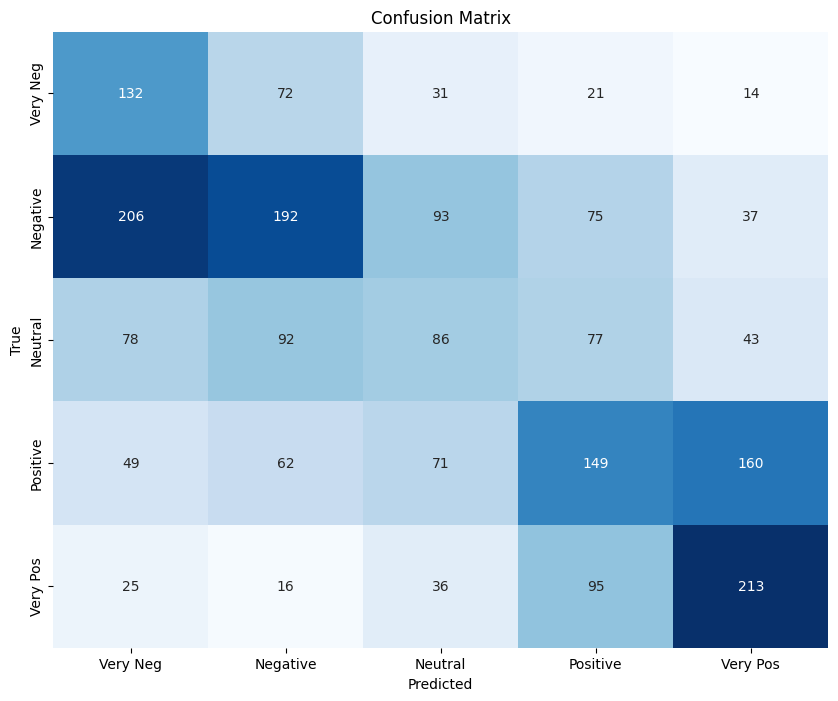


Scikit-learn Metrics:
Confusion Matrix:
[[132  72  31  21  14]
 [206 192  93  75  37]
 [ 78  92  86  77  43]
 [ 49  62  71 149 160]
 [ 25  16  36  95 213]]
Precision: [0.26938776 0.44239631 0.27129338 0.35731415 0.45610278]
Recall: [0.48888889 0.31840796 0.2287234  0.30346232 0.55324675]
F1: [0.34736842 0.37029894 0.24819625 0.32819383 0.5       ]
Macro Precision: 0.3593, Recall: 0.3785, F1: 0.3588


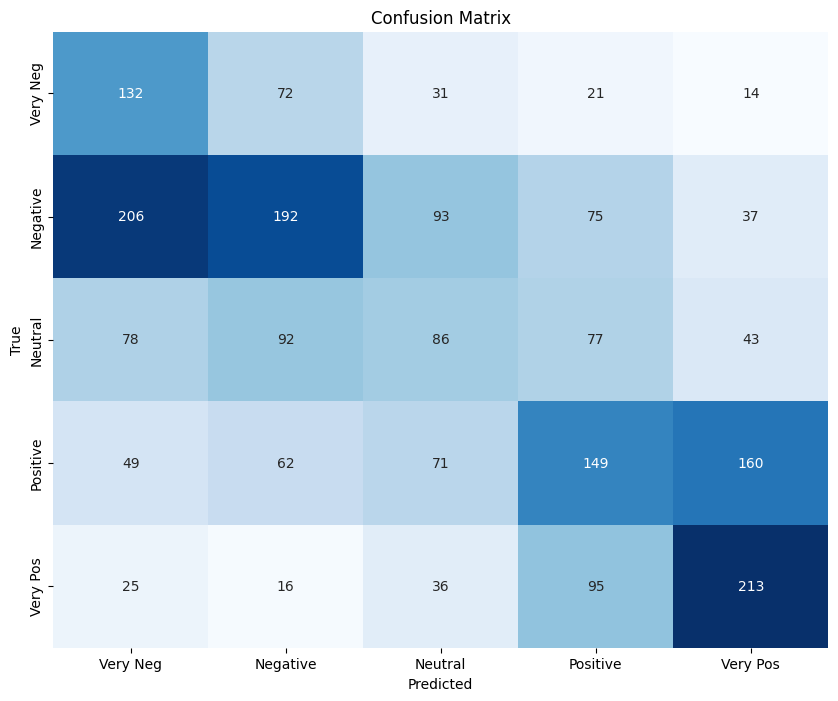

In [602]:
print("\nTraining Naive Bayes Classifier...")
logprior, loglikelihood, V, C = train_NB(train_data)
y_pred_nb_scratch = evaluate_NB(test_data, logprior, loglikelihood, V, C)
accuracy_nb_scratch = accuracy_score(y_test, y_pred_nb_scratch)
print(f"Naive Bayes (Scratch) Accuracy: {accuracy_nb_scratch:.4f}")
#print("\nEvaluation Metrics nb_scratch")    
print_metrices(y_test, y_pred_nb_scratch)


Naive Bayes (scikit-learn) Accuracy: 0.3708
Scratch Metrics:
Confusion Matrix:
[[132  76  30  22  10]
 [200 201  99  67  36]
 [ 70  95  85  85  41]
 [ 41  66  74 160 150]
 [ 25  18  36  96 210]]
Precision: [0.28205128205128205, 0.4407894736842105, 0.2623456790123457, 0.37209302325581395, 0.4697986577181208]
Recall: [0.4888888888888889, 0.3333333333333333, 0.22606382978723405, 0.3258655804480652, 0.5454545454545454]
F1: [0.3577235772357724, 0.3796033994334277, 0.24285714285714285, 0.3474484256243214, 0.5048076923076923]
Macro Precision: 0.3654, Recall: 0.3839, F1: 0.3665


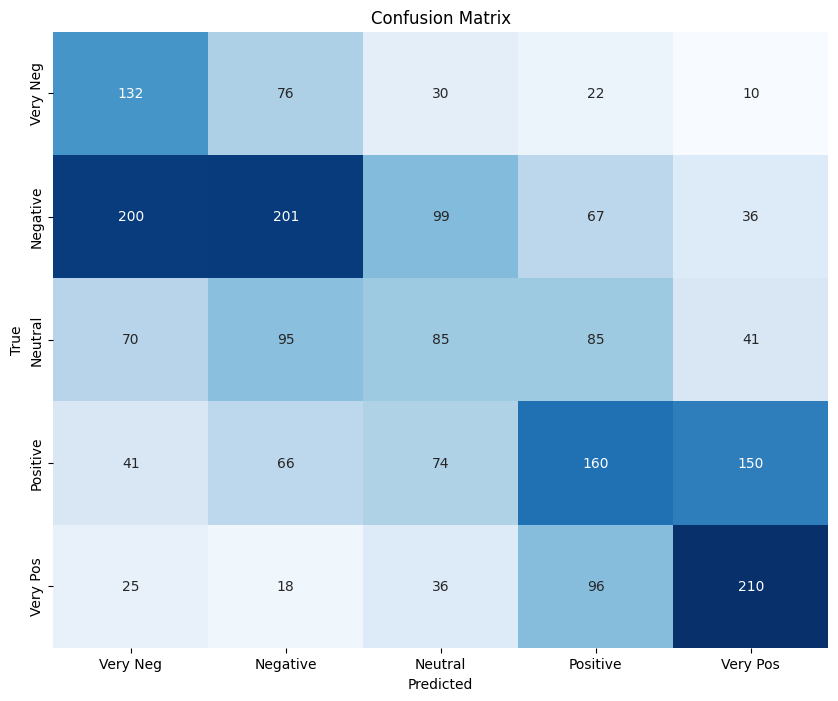


Scikit-learn Metrics:
Confusion Matrix:
[[132  76  30  22  10]
 [200 201  99  67  36]
 [ 70  95  85  85  41]
 [ 41  66  74 160 150]
 [ 25  18  36  96 210]]
Precision: [0.28205128 0.44078947 0.26234568 0.37209302 0.46979866]
Recall: [0.48888889 0.33333333 0.22606383 0.32586558 0.54545455]
F1: [0.35772358 0.3796034  0.24285714 0.34744843 0.50480769]
Macro Precision: 0.3654, Recall: 0.3839, F1: 0.3665


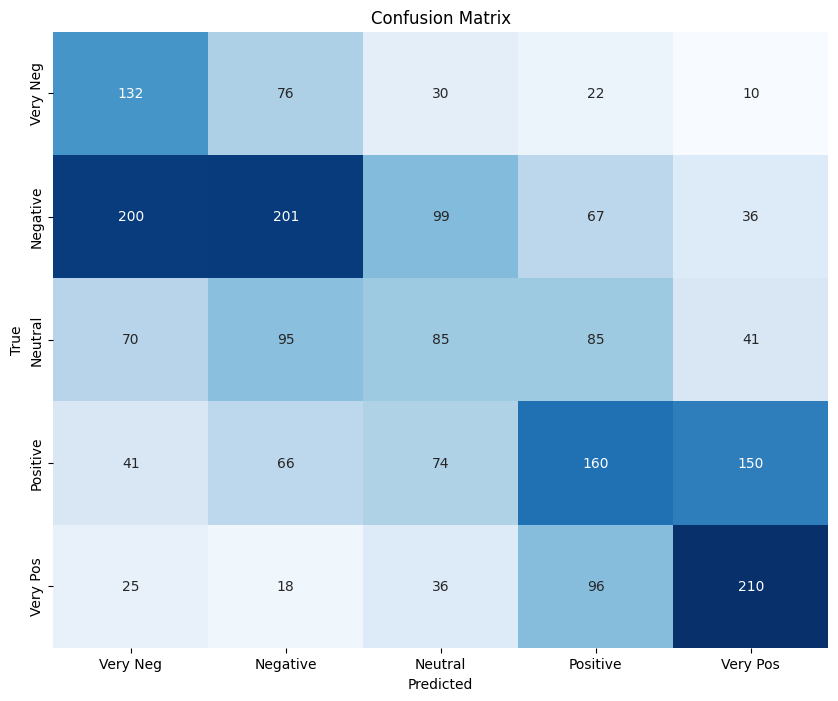

In [603]:
vectorizer_nb, model_nb = train_sk_nb(X_train, y_train)
y_pred_nb_sklearn = evaluate_sk_nb(vectorizer_nb, model_nb, X_test)
accuracy_nb_sklearn = accuracy_score(y_test, y_pred_nb_sklearn)
print(f"\nNaive Bayes (scikit-learn) Accuracy: {accuracy_nb_sklearn:.4f}")
#print("\nEvaluation Metrics nb_sk")
print_metrices(y_test, y_pred_nb_sklearn)

## Logistic Regression


Training Logistic Regression
Logistic Regression (Scratch) Accuracy: 0.2993
Scratch Metrics:
Confusion Matrix:
[[ 88  55  68  26  33]
 [137 136 175  81  74]
 [ 70  70 113  71  52]
 [ 63  64 104 125 135]
 [ 41  27  73  70 174]]
Precision: [0.22055137844611528, 0.38636363636363635, 0.21200750469043153, 0.3351206434316354, 0.3717948717948718]
Recall: [0.32592592592592595, 0.22553897180762852, 0.300531914893617, 0.2545824847250509, 0.45194805194805193]
F1: [0.26307922272047835, 0.2848167539267016, 0.24862486248624863, 0.28935185185185186, 0.40797186400937874]
Macro Precision: 0.3052, Recall: 0.3117, F1: 0.2988


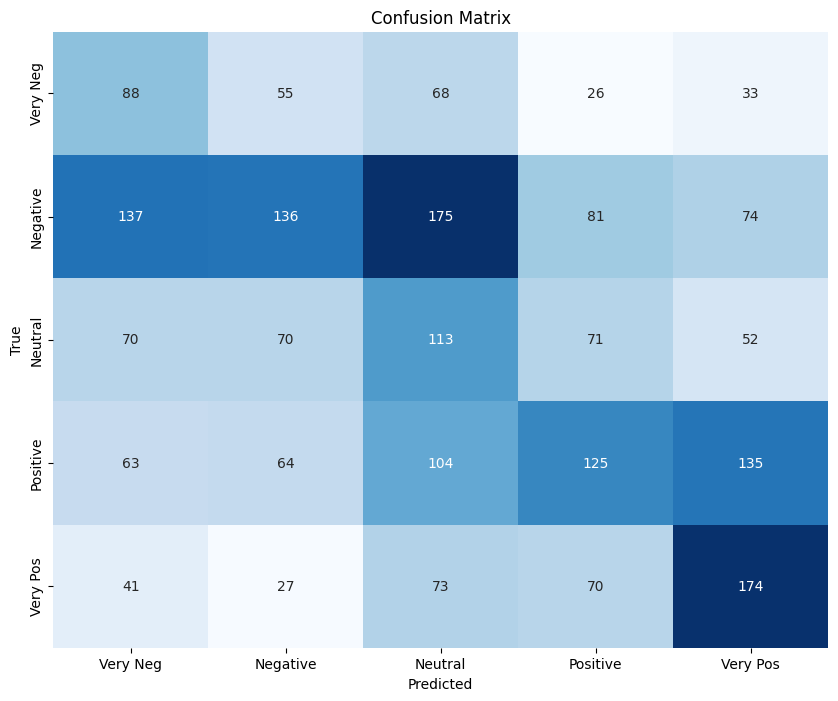


Scikit-learn Metrics:
Confusion Matrix:
[[ 88  55  68  26  33]
 [137 136 175  81  74]
 [ 70  70 113  71  52]
 [ 63  64 104 125 135]
 [ 41  27  73  70 174]]
Precision: [0.22055138 0.38636364 0.2120075  0.33512064 0.37179487]
Recall: [0.32592593 0.22553897 0.30053191 0.25458248 0.45194805]
F1: [0.26307922 0.28481675 0.24862486 0.28935185 0.40797186]
Macro Precision: 0.3052, Recall: 0.3117, F1: 0.2988


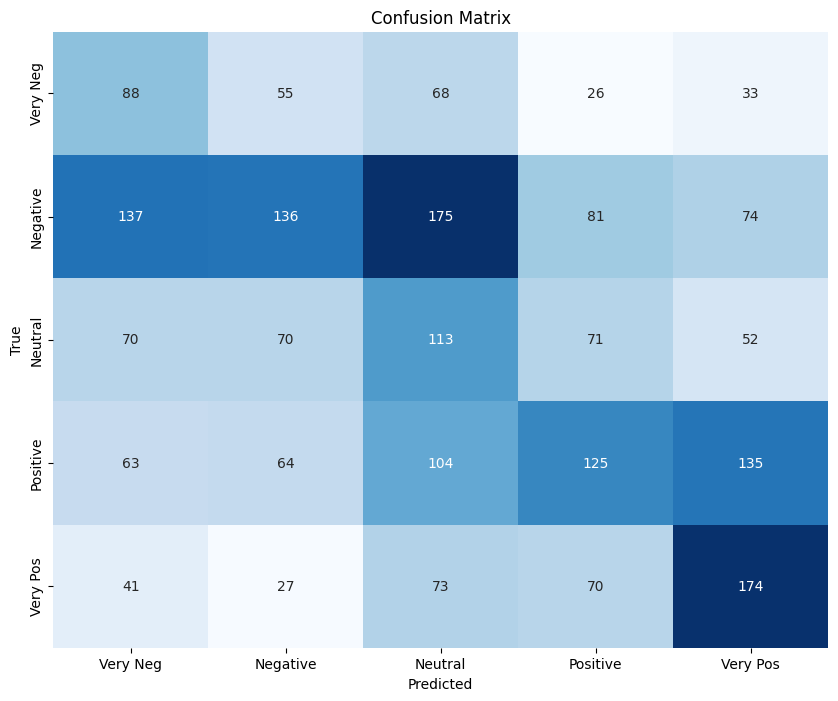

In [604]:
print("\nTraining Logistic Regression")
vectorizer_lr_scratch, weights, bias = train_LR(X_train, y_train)
y_pred_lr_scratch = Evaluate_LR(vectorizer_lr_scratch, weights, bias, X_test)
accuracy_lr_scratch = accuracy_score(y_test, y_pred_lr_scratch)
print(f"Logistic Regression (Scratch) Accuracy: {accuracy_lr_scratch:.4f}")
#print("\nEvaluation Metrics lr_scratch")
print_metrices(y_test, y_pred_lr_scratch) 

c:\Users\ADMIN\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(



Logistic Regression (scikit-learn) Accuracy: 0.3021
Scratch Metrics:
Confusion Matrix:
[[103  56  63  19  29]
 [152 137 194  67  53]
 [ 70  84 110  68  44]
 [ 46  68 117 136 124]
 [ 43  30  83  73 156]]
Precision: [0.24879227053140096, 0.36533333333333334, 0.19400352733686066, 0.3746556473829201, 0.3842364532019704]
Recall: [0.3814814814814815, 0.22719734660033167, 0.2925531914893617, 0.2769857433808554, 0.4051948051948052]
F1: [0.3011695906432748, 0.28016359918200406, 0.23329798515376457, 0.3185011709601874, 0.3944374209860936]
Macro Precision: 0.3134, Recall: 0.3167, F1: 0.3055


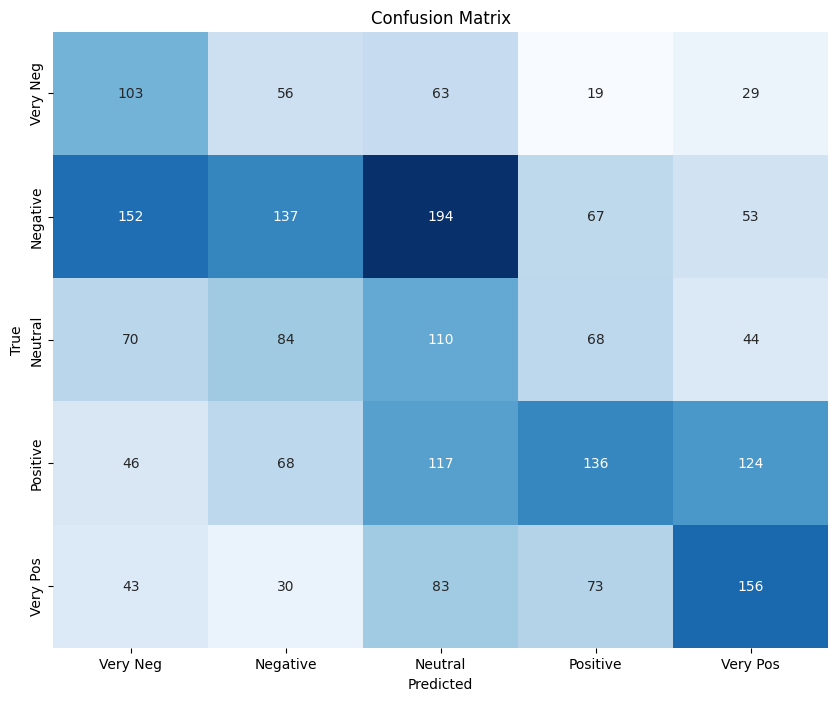


Scikit-learn Metrics:
Confusion Matrix:
[[103  56  63  19  29]
 [152 137 194  67  53]
 [ 70  84 110  68  44]
 [ 46  68 117 136 124]
 [ 43  30  83  73 156]]
Precision: [0.24879227 0.36533333 0.19400353 0.37465565 0.38423645]
Recall: [0.38148148 0.22719735 0.29255319 0.27698574 0.40519481]
F1: [0.30116959 0.2801636  0.23329799 0.31850117 0.39443742]
Macro Precision: 0.3134, Recall: 0.3167, F1: 0.3055


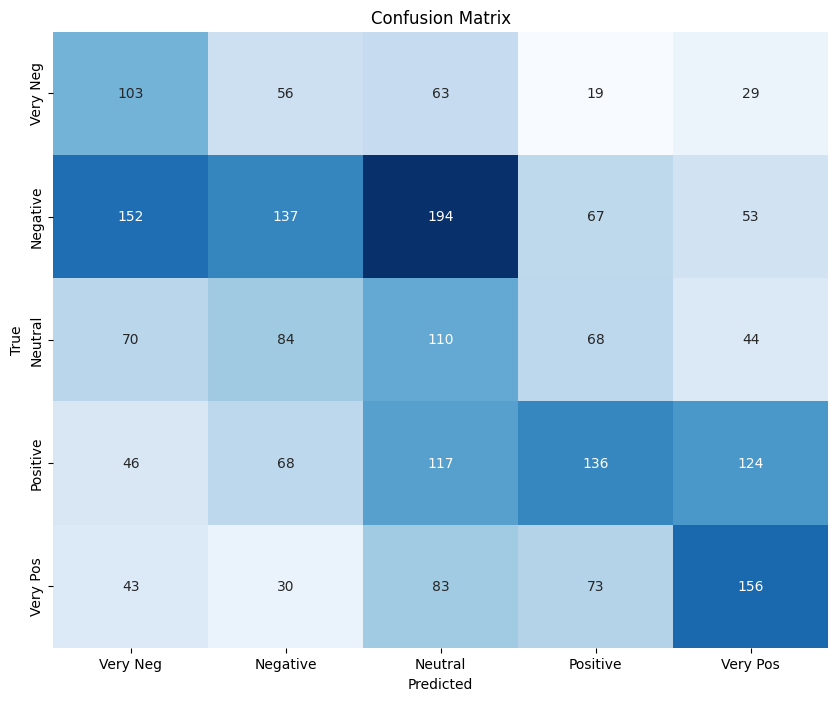

In [605]:
vectorizer_lr, model_lr = train_sk_LR(X_train, y_train)
y_pred_lr = evaluate_sk_LR(vectorizer_lr, model_lr, X_test)
accuracy_lr = accuracy_score(y_test, y_pred_lr)
print(f"\nLogistic Regression (scikit-learn) Accuracy: {accuracy_lr:.4f}")
#print("\nEvaluation Metrics lr_sk")
print_metrices(y_test, y_pred_lr)  


SGDClassifier (scikit-learn) Accuracy: 0.3016
Scratch Metrics:
Confusion Matrix:
[[100  61  61  18  30]
 [140 155 182  69  57]
 [ 72  82 105  71  46]
 [ 53  78 103 125 132]
 [ 41  34  79  75 156]]
Precision: [0.24630541871921183, 0.3780487804878049, 0.19811320754716982, 0.34916201117318435, 0.37054631828978624]
Recall: [0.37037037037037035, 0.2570480928689884, 0.27925531914893614, 0.2545824847250509, 0.4051948051948052]
F1: [0.2958579881656805, 0.3060217176702863, 0.2317880794701987, 0.29446407538280334, 0.3870967741935484]
Macro Precision: 0.3084, Recall: 0.3133, F1: 0.3030


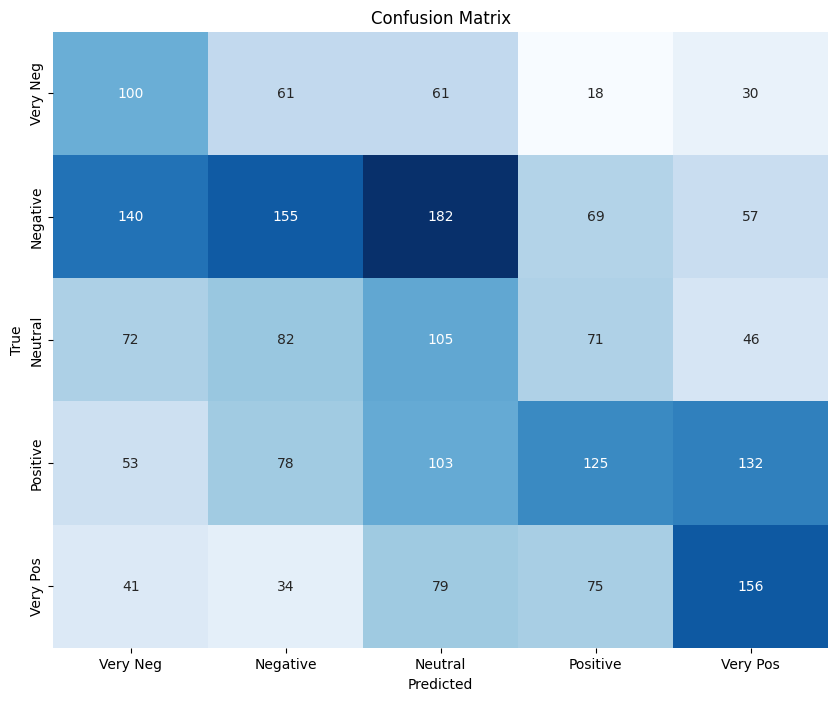


Scikit-learn Metrics:
Confusion Matrix:
[[100  61  61  18  30]
 [140 155 182  69  57]
 [ 72  82 105  71  46]
 [ 53  78 103 125 132]
 [ 41  34  79  75 156]]
Precision: [0.24630542 0.37804878 0.19811321 0.34916201 0.37054632]
Recall: [0.37037037 0.25704809 0.27925532 0.25458248 0.40519481]
F1: [0.29585799 0.30602172 0.23178808 0.29446408 0.38709677]
Macro Precision: 0.3084, Recall: 0.3133, F1: 0.3030


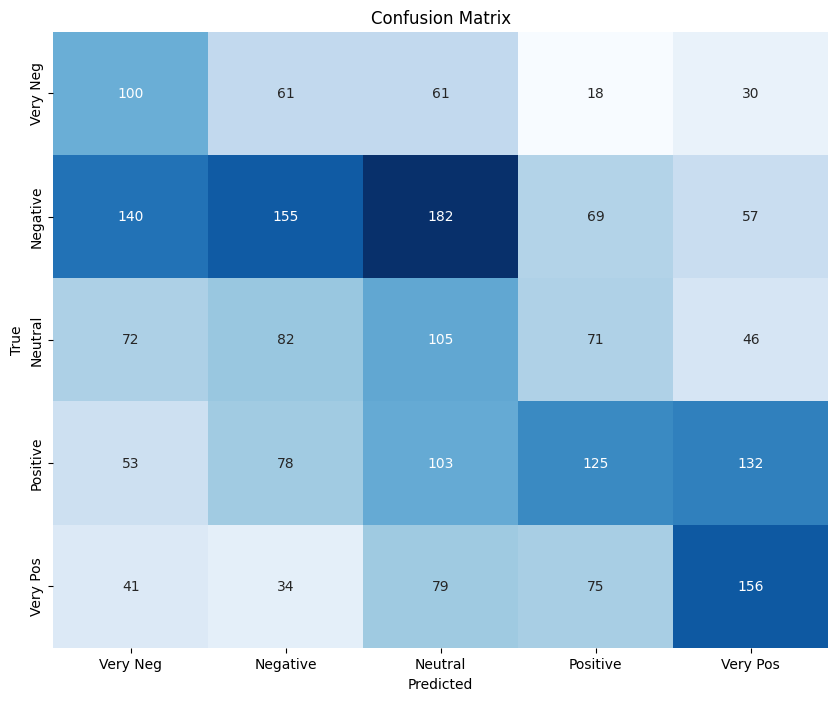

In [606]:
vectorizer_sgd, model_sgd = train_sgd(X_train, y_train)
y_pred_sgd = evaluate_sk_LR(vectorizer_sgd, model_sgd, X_test)
accuracy_sgd = accuracy_score(y_test, y_pred_sgd)
print(f"\nSGDClassifier (scikit-learn) Accuracy: {accuracy_sgd:.4f}")
#print("\nEvaluation Metrics sgd_sk")
print_metrices(y_test, y_pred_sgd)  

LogisticRegression Performs Better With Larger Dataset: Its optimized solvers and regularization prevent overfitting and ensure robust convergence,
critical for noisy text datasets unlike the stochastic approaches.But, NB is typically better than LR when the dataset is not large, especially for text tasks.

SGDClassifier is most comparable to the from-scratch implementation,
as both use SGD with mini-batch updates and data shuffling. However,
differences in learning rate adaptation and convergence criteria may lead to slight performance gaps.